# Results: baseline vs component-aware recognition

Runs come from `scripts/train.py` (summaries in `results/*/summary.json`), test predictions
from `scripts/predict_test.py`, zero-shot scores from `scripts/zero_shot.py`.
Test set: 400 ETL9B writer sheets never used in training. Questions:

1. Does adding component heads change top-1 / top-5 accuracy, and how does that depend on
   training samples per class?
2. Which characters do the full-data models confuse, and does the component-aware model make
   different mistakes?
3. Can the component-aware model recognise the 300 characters hidden from training
   (`data/heldout_characters.txt`) from predicted components alone?

In [1]:
import json
import sys
from collections import Counter
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

sys.path.insert(0, "src")
from kanji_components.etl9b import Etl9bCache

RESULTS_DIR = Path("results")

In [2]:
SERIES_BLUE = "#2a78d6"
SERIES_ORANGE = "#e07b39"
TEXT_SECONDARY = "#52514e"
GRID_GRAY = "#e6e5e1"

plt.rcParams.update({
    "figure.dpi": 100,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.edgecolor": GRID_GRAY,
    "axes.labelcolor": TEXT_SECONDARY,
    "xtick.color": TEXT_SECONDARY,
    "ytick.color": TEXT_SECONDARY,
    "axes.grid": True,
    "axes.grid.axis": "y",
    "grid.color": GRID_GRAY,
    "axes.axisbelow": True,
    "font.family": ["Noto Sans CJK JP", "DejaVu Sans"],
})

## 1. Baseline vs component-aware at 5 / 20 / all samples per class

In [3]:
rows = []
for summary_path in sorted(RESULTS_DIR.glob("*/summary.json")):
    summary = json.loads(summary_path.read_text())
    if summary["arguments"].get("exclude_characters"):
        continue
    rows.append({
        "run": summary["name"],
        "samples_per_class": summary["arguments"]["samples_per_class"] or 200,
        "model": "component-aware" if summary["arguments"]["components"] else "baseline",
        "train_images": summary["train_samples"],
        "test_top1": summary["test"]["top1"],
        "test_top5": summary["test"]["top5"],
        "nested_f1": summary["test"].get("nested_f1_micro"),
        "positioned_f1": summary["test"].get("positioned_f1_micro"),
    })
runs = pd.DataFrame(rows).sort_values(["samples_per_class", "model"])
print(len(runs), "runs")
runs.round(4)

6 runs


,run,samples_per_class,model,train_images,test_top1,test_top5,nested_f1,positioned_f1
1,baseline_5,5,baseline,15180,0.8887,0.9831,NaN,NaN
4,multitask_5,5,component-aware,15180,0.9114,0.9881,0.3748,0.4739
0,baseline_20,20,baseline,60720,0.9791,0.9978,NaN,NaN
3,multitask_20,20,component-aware,60720,0.9825,0.9982,0.4750,0.6280
2,baseline_all,200,baseline,485760,0.9923,0.9993,NaN,NaN
5,multitask_all,200,component-aware,485760,0.9929,0.9995,0.5712,0.7391


`samples_per_class = 200` means every training writer was used (160 per class after the writer split).

In [4]:
comparison = runs.pivot(index="samples_per_class", columns="model", values=["test_top1", "test_top5"])
comparison["gain_top1_points"] = 100 * (
    comparison[("test_top1", "component-aware")] - comparison[("test_top1", "baseline")])
comparison["gain_top5_points"] = 100 * (
    comparison[("test_top5", "component-aware")] - comparison[("test_top5", "baseline")])
comparison.round(4)

/tmp/ipykernel_345803/4186434481.py:2: Pandas4Warning: Setting a new column on a DataFrame with a MultiIndex using a key that is not a full-length tuple is deprecated and will raise in a future version. Use a full-length tuple key instead.
  comparison["gain_top1_points"] = 100 * (
/tmp/ipykernel_345803/4186434481.py:4: Pandas4Warning: Setting a new column on a DataFrame with a MultiIndex using a key that is not a full-length tuple is deprecated and will raise in a future version. Use a full-length tuple key instead.
  comparison["gain_top5_points"] = 100 * (


test_top1                 test_top5                  \
model              baseline component-aware  baseline component-aware   
samples_per_class                                                       
5                    0.8887          0.9114    0.9831          0.9881   
20                   0.9791          0.9825    0.9978          0.9982   
200                  0.9923          0.9929    0.9993          0.9995   

                  gain_top1_points gain_top5_points  
model                                                
samples_per_class                                    
5                           2.2677           0.5006  
20                          0.3475           0.0461  
200                         0.0511           0.0214

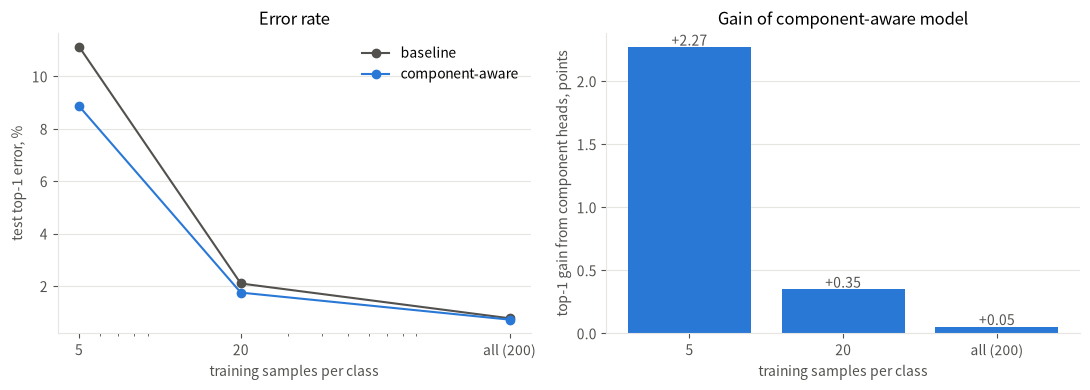

In [5]:
figure, (left, right) = plt.subplots(1, 2, figsize=(11, 4))
for model, color in [("baseline", TEXT_SECONDARY), ("component-aware", SERIES_BLUE)]:
    subset = runs[runs["model"] == model]
    left.plot(subset["samples_per_class"], 100 * (1 - subset["test_top1"]), marker="o", color=color, label=model)
left.set_xscale("log")
left.set_xticks([5, 20, 200], ["5", "20", "all (200)"])
left.set_xlabel("training samples per class")
left.set_ylabel("test top-1 error, %")
left.set_title("Error rate")
left.legend(frameon=False)
right.bar(["5", "20", "all (200)"], comparison["gain_top1_points"], color=SERIES_BLUE)
for position, value in enumerate(comparison["gain_top1_points"]):
    right.text(position, value, f"+{value:.2f}", ha="center", va="bottom", color=TEXT_SECONDARY)
right.set_xlabel("training samples per class")
right.set_ylabel("top-1 gain from component heads, points")
right.set_title("Gain of component-aware model")
plt.tight_layout()

Each cell is one training seed. Hypothesis: the gain at 20 and 200 samples per class is within
seed-to-seed variation; the gain at 5 is not. Repeated seeds would settle this.

## 1b. Beyond top-1 accuracy: error rate, per-class view, confident mistakes, paired test

From `results/*/test_predictions.npz`, all on the same 60,723 test images.
`error_rate_pct`: share of images read wrongly. `mean_class_accuracy`: accuracy averaged over the
3036 characters, so every character counts equally (= macro recall). `macro_precision` and
`macro_f1` average per-character precision and F1 the same way; `weighted_f1` weights each
character by its test images. Micro-F1 equals top-1 accuracy for single-label classification. `worst_10pct_classes_accuracy`: mean accuracy of
the 303 hardest characters. `classes_below_90pct`: characters recognised in under 90% of their test
images. `confident_mistakes_pct`: images where the model gave its answer probability ≥ 0.9 and
was wrong. `unsure_pct`: images where the answer probability was below 0.5.

In [6]:
from math import comb

CONFIDENT = 0.9
UNSURE = 0.5


def exact_mcnemar_p_value(fixed, broken):
    trials = fixed + broken
    tail = sum(comb(trials, k) for k in range(min(fixed, broken) + 1)) / 2 ** trials
    return min(1.0, 2 * tail)


def classification_metrics(prediction):
    labels = prediction["labels"].astype(int)
    top5 = prediction["top5"].astype(int)
    correct = top5[:, 0] == labels
    class_count = len(characters)
    true_positive = np.bincount(labels[correct], minlength=class_count)
    actual_count = np.bincount(labels, minlength=class_count)
    predicted_count = np.bincount(top5[:, 0], minlength=class_count)
    per_class_accuracy = true_positive / actual_count
    per_class_precision = true_positive / np.maximum(predicted_count, 1)
    per_class_f1 = 2 * true_positive / np.maximum(predicted_count + actual_count, 1)
    confidence = prediction["top5_probabilities"][:, 0]
    return {
        "top1": correct.mean(),
        "top3": (top5[:, :3] == labels[:, None]).any(1).mean(),
        "top5": (top5 == labels[:, None]).any(1).mean(),
        "error_rate_pct": 100 * (1 - correct.mean()),
        "mean_class_accuracy": per_class_accuracy.mean(),
        "macro_precision": per_class_precision.mean(),
        "macro_f1": per_class_f1.mean(),
        "weighted_f1": (per_class_f1 * actual_count).sum() / actual_count.sum(),
        "worst_10pct_classes_accuracy": np.sort(per_class_accuracy)[: class_count // 10].mean(),
        "classes_below_90pct": int((per_class_accuracy < 0.9).sum()),
        "confident_mistakes_pct": 100 * ((confidence >= CONFIDENT) & ~correct).mean(),
        "unsure_pct": 100 * (confidence < UNSURE).mean(),
    }

In [7]:
archive = np.load("data/component_targets.npz", allow_pickle=False)
characters = list(archive["characters"])
metric_rows = []
for _, run in runs.iterrows():
    prediction = np.load(RESULTS_DIR / run["run"] / "test_predictions.npz")
    metric_rows.append({"samples_per_class": run["samples_per_class"], "model": run["model"],
                        **classification_metrics(prediction)})
metrics = pd.DataFrame(metric_rows).set_index(["samples_per_class", "model"])
print(len(metrics), "runs scored on", len(prediction["labels"]), "test images each")
metrics.round(4).T

6 runs scored on 60723 test images each


samples_per_class                   5                         20   \
model                          baseline component-aware  baseline   
top1                             0.8887          0.9114    0.9791   
top3                             0.9702          0.9778    0.9963   
top5                             0.9831          0.9881    0.9978   
error_rate_pct                  11.1292          8.8616    2.0931   
mean_class_accuracy              0.8881          0.9111    0.9789   
macro_precision                  0.8927          0.9137    0.9795   
macro_f1                         0.8858          0.9089    0.9786   
weighted_f1                      0.8880          0.9107    0.9791   
worst_10pct_classes_accuracy     0.6328          0.6763    0.8920   
classes_below_90pct           1329.0000       1030.0000  151.0000   
confident_mistakes_pct           0.0972          0.1070    0.2470   
unsure_pct                      14.9548         12.0877    1.0820   

samples_per_class                                 200                  
model                        component-aware baseline component-aware  
top1                                  0.9825   0.9923          0.9929  
top3                                  0.9970   0.9988          0.9990  
top5                                  0.9982   0.9993          0.9995  
error_rate_pct                        1.7456   0.7658          0.7147  
mean_class_accuracy                   0.9824   0.9923          0.9928  
macro_precision                       0.9827   0.9925          0.9930  
macro_f1                              0.9821   0.9922          0.9927  
weighted_f1                           0.9826   0.9924          0.9929  
worst_10pct_classes_accuracy          0.9014   0.9380          0.9379  
classes_below_90pct                 112.0000  29.0000         28.0000  
confident_mistakes_pct                0.1993   0.1960          0.1746  
unsure_pct                            0.9288   0.1812          0.1696

⚠️ Thresholds 0.9 for "confident" and 0.5 for "unsure" are arbitrary; other cut-offs change the
two confidence rows but not their ordering between models.

In [8]:
paired_rows = []
for samples_per_class, group in runs.groupby("samples_per_class"):
    named = {row["model"]: np.load(RESULTS_DIR / row["run"] / "test_predictions.npz") for _, row in group.iterrows()}
    correct = {model: p["top5"][:, 0] == p["labels"] for model, p in named.items()}
    fixed = int((correct["component-aware"] & ~correct["baseline"]).sum())
    broken = int((correct["baseline"] & ~correct["component-aware"]).sum())
    baseline_errors = int((~correct["baseline"]).sum())
    component_errors = int((~correct["component-aware"]).sum())
    paired_rows.append({"samples_per_class": samples_per_class, "baseline_errors": baseline_errors,
                        "component_aware_errors": component_errors,
                        "error_reduction_pct": 100 * (baseline_errors - component_errors) / baseline_errors,
                        "fixed": fixed, "broken": broken, "mcnemar_p_value": exact_mcnemar_p_value(fixed, broken)})
paired = pd.DataFrame(paired_rows).set_index("samples_per_class")
paired.round(4)

,baseline_errors,component_aware_errors,error_reduction_pct,fixed,broken,mcnemar_p_value
samples_per_class,,,,,,
5,6758,5381,20.3759,3368,1991,0.0000
20,1271,1060,16.6011,708,497,0.0000
200,465,434,6.6667,240,209,0.1568


`fixed`: images the baseline got wrong and the component-aware model got right; `broken`: the
reverse. If the two models were equally good, `fixed` and `broken` would be about equal; the
McNemar p-value is the probability of a split at least this uneven by chance.
⚠️ The test treats images as independent; images from the same writer sheet are correlated, so
the p-values are optimistic.

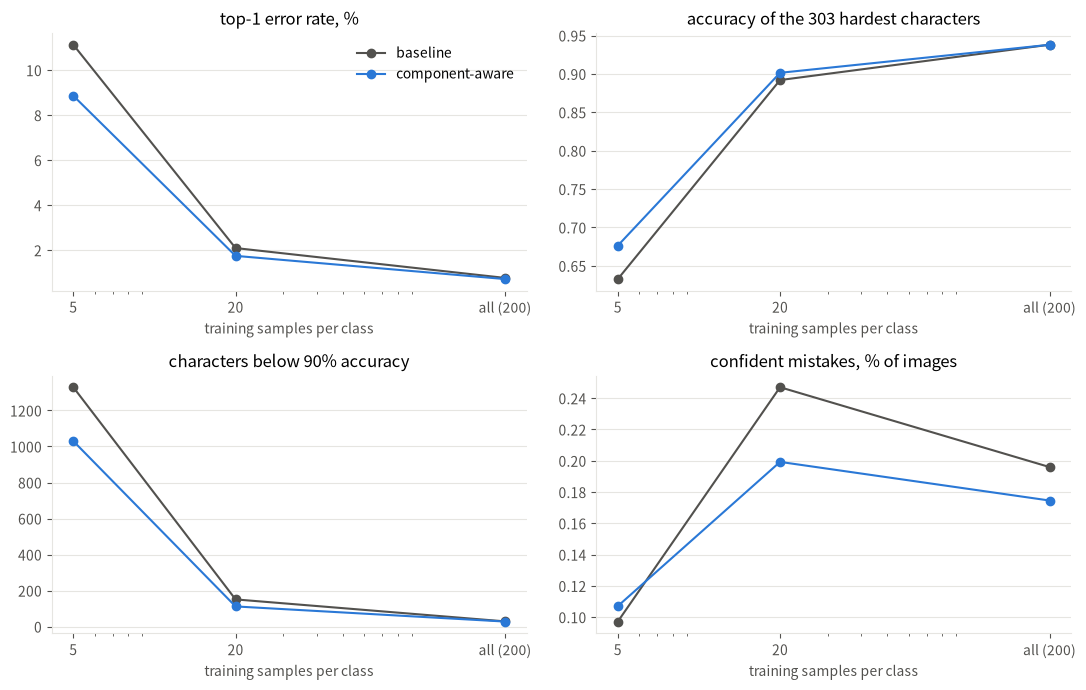

In [9]:
panels = [("error_rate_pct", "top-1 error rate, %"), ("worst_10pct_classes_accuracy", "accuracy of the 303 hardest characters"),
          ("classes_below_90pct", "characters below 90% accuracy"), ("confident_mistakes_pct", "confident mistakes, % of images")]
figure, axes = plt.subplots(2, 2, figsize=(11, 7))
for axis, (column, title) in zip(axes.ravel(), panels):
    for model, color in [("baseline", TEXT_SECONDARY), ("component-aware", SERIES_BLUE)]:
        series = metrics.xs(model, level="model")[column]
        axis.plot(series.index, series.values, marker="o", color=color, label=model)
    axis.set_xscale("log")
    axis.set_xticks([5, 20, 200], ["5", "20", "all (200)"])
    axis.set_title(title)
    axis.set_xlabel("training samples per class")
axes[0, 0].legend(frameon=False)
plt.tight_layout()

## 2. Confusions of the full-data models

In [10]:
archive = np.load("data/component_targets.npz", allow_pickle=False)
characters = list(archive["characters"])
nested_vocabulary = list(archive["nested_vocabulary"])
positioned_vocabulary = list(archive["positioned_vocabulary"])
nested_targets = archive["nested_targets"] > 0.5
positioned_targets = archive["positioned_targets"] > 0.5
predictions = {name: np.load(RESULTS_DIR / name / "test_predictions.npz")
               for name in ["baseline_all", "multitask_all"]}
labels = predictions["baseline_all"]["labels"].astype(int)
assert (labels == predictions["multitask_all"]["labels"]).all()
print(len(labels), "test images,", len(characters), "classes")

60723 test images, 3036 classes


In [11]:
def positioned_components(label):
    return " ".join(positioned_vocabulary[i] for i in np.flatnonzero(positioned_targets[label]))


top1 = {name: prediction["top5"][:, 0].astype(int) for name, prediction in predictions.items()}
correct = {name: top1[name] == labels for name in top1}
per_class = pd.DataFrame({
    "character": characters,
    "test_images": np.bincount(labels, minlength=len(characters)),
    "baseline_correct": np.bincount(labels, weights=correct["baseline_all"], minlength=len(characters)).astype(int),
    "multitask_correct": np.bincount(labels, weights=correct["multitask_all"], minlength=len(characters)).astype(int),
})
per_class["baseline_accuracy"] = per_class["baseline_correct"] / per_class["test_images"]
per_class["multitask_accuracy"] = per_class["multitask_correct"] / per_class["test_images"]
per_class["components"] = [positioned_components(label) for label in range(len(characters))]
per_class.to_csv(RESULTS_DIR / "per_class_accuracy.csv", index=False)
print("saved results/per_class_accuracy.csv,", len(per_class), "rows")
per_class.sort_values("baseline_accuracy").head(15)

saved results/per_class_accuracy.csv, 3036 rows


,character,test_images,baseline_correct,multitask_correct,baseline_accuracy,multitask_accuracy,components
1360,梁,18,15,18,0.833333,1.000000,氵@left 木@bottom 丶@none
3,え,26,22,24,0.846154,0.923077,
609,壬,23,20,20,0.869565,0.869565,王@none
835,帥,23,20,20,0.869565,0.869565,丿@none
668,姶,16,14,15,0.875000,0.937500,女@left 合@right
2911,頴,16,14,15,0.875000,0.937500,示@bottom
347,助,25,22,24,0.880000,0.960000,力@right
20,ず,25,22,23,0.880000,0.920000,
2361,藩,17,15,17,0.882353,1.000000,艹@top
2924,飛,17,15,16,0.882353,0.941176,


In [12]:
def confusion_pairs(name):
    wrong = ~correct[name]
    counts = Counter(zip(labels[wrong], top1[name][wrong]))
    table = pd.DataFrame([(characters[t], characters[p], n) for (t, p), n in counts.items()],
                         columns=["true", "predicted", name])
    return table.set_index(["true", "predicted"])


confusions = confusion_pairs("baseline_all").join(confusion_pairs("multitask_all"), how="outer").fillna(0).astype(int)
confusions = confusions.sort_values("baseline_all", ascending=False)
confusions.to_csv(RESULTS_DIR / "confusion_pairs.csv")
print("saved results/confusion_pairs.csv:", len(confusions), "distinct (true, predicted) pairs")
print("errors: baseline", (~correct["baseline_all"]).sum(), " component-aware", (~correct["multitask_all"]).sum())
confusions.head(25)

saved results/confusion_pairs.csv: 660 distinct (true, predicted) pairs
errors: baseline 465  component-aware 434


,,baseline_all,multitask_all
true,predicted,,
え,之,4,2
帥,師,3,3
壬,王,3,3
助,肋,3,1
梁,染,2,0
始,姶,2,2
且,旦,2,1
藩,蕃,2,0
頴,穎,2,1


`results/confusion_pairs.csv` is the sparse confusion matrix: every off-diagonal cell with its count
for both models. `results/per_class_accuracy.csv` holds the diagonal.

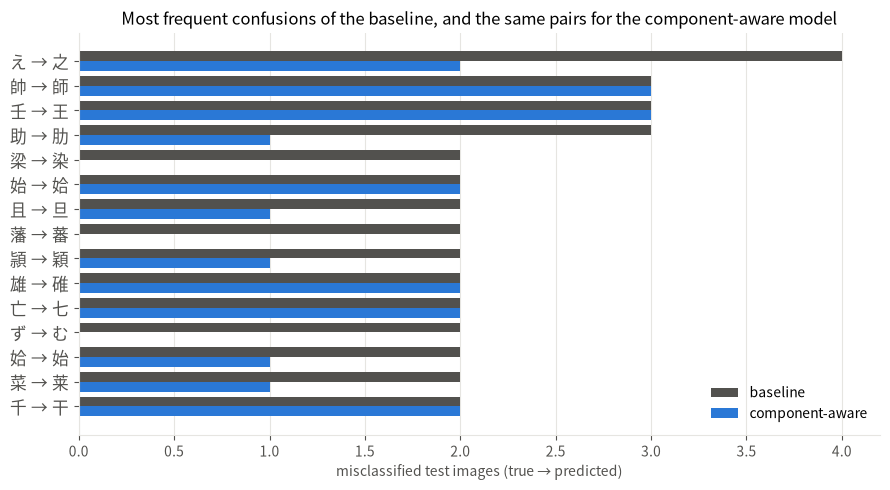

In [13]:
top_pairs = confusions.head(15)
pair_labels = [f"{t} → {p}" for t, p in top_pairs.index]
positions = np.arange(len(top_pairs))
figure, axis = plt.subplots(figsize=(9, 5))
axis.barh(positions - 0.2, top_pairs["baseline_all"], height=0.4, color=TEXT_SECONDARY, label="baseline")
axis.barh(positions + 0.2, top_pairs["multitask_all"], height=0.4, color=SERIES_BLUE, label="component-aware")
axis.set_yticks(positions, pair_labels, fontsize=12)
axis.invert_yaxis()
axis.grid(axis="x")
axis.grid(False, axis="y")
axis.set_xlabel("misclassified test images (true → predicted)")
axis.set_title("Most frequent confusions of the baseline, and the same pairs for the component-aware model")
axis.legend(frameon=False)
plt.tight_layout()

In [14]:
true_index = np.array([characters.index(t) for t, _ in confusions.index])
predicted_index = np.array([characters.index(p) for _, p in confusions.index])
confusions["shared_nested"] = (nested_targets[true_index] & nested_targets[predicted_index]).sum(1)
confusions["shared_positioned"] = (positioned_targets[true_index] & positioned_targets[predicted_index]).sum(1)
random_pairs = np.random.default_rng(0).integers(0, len(characters), size=(len(confusions), 2))
random_shared = (nested_targets[random_pairs[:, 0]] & nested_targets[random_pairs[:, 1]]).sum(1)
share_confused = (confusions["shared_nested"] > 0).mean()
share_random = (random_shared > 0).mean()
print(f"confused pairs sharing a nested component: {share_confused:.1%} (n={len(confusions)})")
print(f"random class pairs sharing a nested component: {share_random:.1%} (n={len(random_pairs)})")

confused pairs sharing a nested component: 74.1% (n=660)
random class pairs sharing a nested component: 22.0% (n=660)


⚠️ The random-pair reference uses one draw of uniformly random class pairs, the same number as
confused pairs. A different draw moves the reference share slightly.

In [15]:
fixed = correct["multitask_all"] & ~correct["baseline_all"]
broken = correct["baseline_all"] & ~correct["multitask_all"]
print(f"fixed by component heads: {fixed.sum()}   broken by component heads: {broken.sum()}")
print(f"wrong in both: {(~correct['baseline_all'] & ~correct['multitask_all']).sum()}")
fixed_pairs = Counter(zip(labels[fixed], top1["baseline_all"][fixed]))
pd.DataFrame([(characters[t], characters[p], n, positioned_components(t), positioned_components(p))
              for (t, p), n in fixed_pairs.most_common(15)],
             columns=["true", "baseline predicted", "fixed images", "true components", "predicted components"])

fixed by component heads: 240   broken by component heads: 209
wrong in both: 225


,true,baseline predicted,fixed images,true components,predicted components
0,助,肋,2,力@right,月@left 力@right
1,梁,染,2,氵@left 木@bottom 丶@none,氵@left 木@bottom
2,園,圏,2,囗@kamae,囗@kamae
3,藩,蕃,2,艹@top,艹@top
4,え,之,2,,亠@none
5,褐,掲,1,衤@left 曷@right,扌@left 曷@right
6,此,比,1,匕@right,匕@right
7,染,深,1,氵@left 木@bottom,氵@left 木@bottom
8,憤,慎,1,忄@left,忄@left
9,堤,提,1,土@left,扌@left


In [16]:
cache = Etl9bCache()
assert cache.characters == characters
test_indices = predictions["baseline_all"]["indices"]
print(cache.images.shape)

(607200, 64, 64)


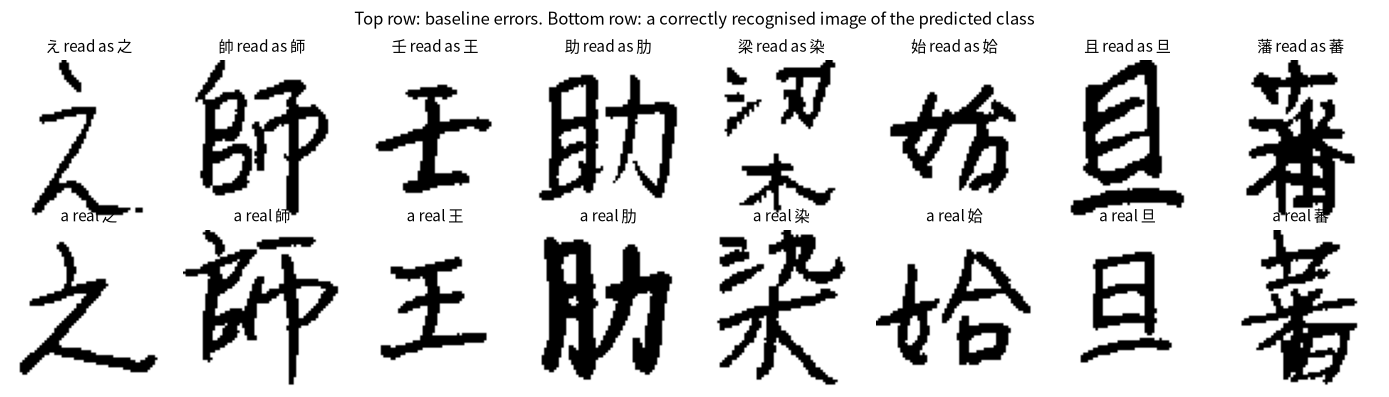

In [17]:
example_pairs = list(confusions.head(8).index)
figure, axes = plt.subplots(2, 8, figsize=(14, 4))
for column, (true_character, predicted_character) in enumerate(example_pairs):
    true_label, predicted_label = characters.index(true_character), characters.index(predicted_character)
    wrong_rows = np.flatnonzero((labels == true_label) & (top1["baseline_all"] == predicted_label))
    right_rows = np.flatnonzero((labels == predicted_label) & correct["baseline_all"])
    axes[0, column].imshow(cache.images[test_indices[wrong_rows[0]]], cmap="gray_r")
    axes[0, column].set_title(f"{true_character} read as {predicted_character}", fontsize=11)
    axes[1, column].imshow(cache.images[test_indices[right_rows[0]]], cmap="gray_r")
    axes[1, column].set_title(f"a real {predicted_character}", fontsize=11)
for axis in axes.ravel():
    axis.axis("off")
figure.suptitle("Top row: baseline errors. Bottom row: a correctly recognised image of the predicted class")
plt.tight_layout()

## 3. Zero-shot recognition of 300 held-out characters

`heldout_multitask` was trained on the other 2736 classes with all training writers. For a test
image of a held-out character the predicted component probabilities are matched against the
KanjiVG component vector of every candidate character (Bernoulli log-likelihood,
`scripts/zero_shot.py`). Candidate sets: the 300 held-out characters, or all 3036.

In [18]:
heldout_characters = Path("data/heldout_characters.txt").read_text().strip()
zero_shot = json.loads((RESULTS_DIR / "heldout_multitask" / "zero_shot.json").read_text())
zero_shot_predictions = pd.read_csv(RESULTS_DIR / "heldout_multitask" / "zero_shot_predictions.csv")
print(len(heldout_characters), "held-out characters,", len(zero_shot_predictions), "held-out test images")
zero_shot_table = pd.DataFrame({key: value for key, value in zero_shot.items() if isinstance(value, dict)}).T
zero_shot_table["chance_top1"] = [1 / 300, 1 / 3036, 1 / 3036, 1 / 3036, 1 / 3036]
zero_shot_table

300 held-out characters, 5988 held-out test images


,top1,top5,images,chance_top1
components_within_heldout,0.673681,0.884269,5988.0,0.003333
components_within_all,0.279559,0.444723,5988.0,0.000329
character_head_on_heldout,0.000000,0.000000,5988.0,0.000329
components_within_all_on_seen,0.815274,0.937389,54735.0,0.000329
character_head_on_seen,0.993240,0.999470,54735.0,0.000329


Rows: `components_within_heldout` and `components_within_all` are the held-out images recognised by
component matching; `character_head_on_heldout` is the ordinary classifier output on the same
images (it never saw these classes); the `_on_seen` rows are the 2736 trained classes for reference.
⚠️ Component probabilities are clipped to [1e-4, 1 − 1e-4] before the log-likelihood; a tighter
floor punishes a single confident miss more.

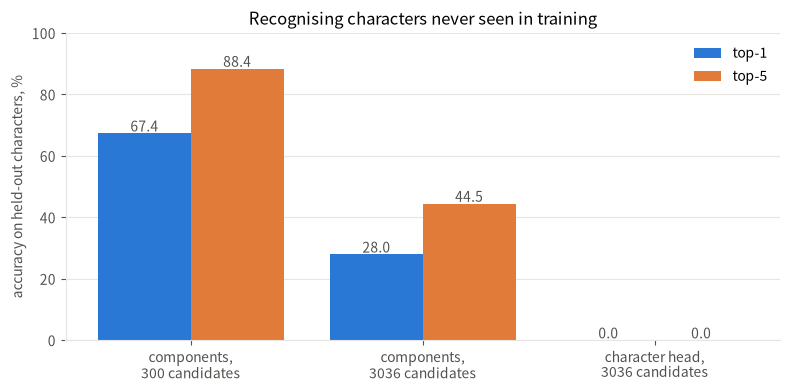

In [19]:
figure, axis = plt.subplots(figsize=(8, 4))
methods = ["components_within_heldout", "components_within_all", "character_head_on_heldout"]
names = ["components,\n300 candidates", "components,\n3036 candidates", "character head,\n3036 candidates"]
positions = np.arange(len(methods))
axis.bar(positions - 0.2, [100 * zero_shot[m]["top1"] for m in methods], width=0.4, color=SERIES_BLUE, label="top-1")
axis.bar(positions + 0.2, [100 * zero_shot[m]["top5"] for m in methods], width=0.4, color=SERIES_ORANGE, label="top-5")
for position, method in zip(positions, methods):
    axis.text(position - 0.2, 100 * zero_shot[method]["top1"], f"{100 * zero_shot[method]['top1']:.1f}",
              ha="center", va="bottom", color=TEXT_SECONDARY)
    axis.text(position + 0.2, 100 * zero_shot[method]["top5"], f"{100 * zero_shot[method]['top5']:.1f}",
              ha="center", va="bottom", color=TEXT_SECONDARY)
axis.set_xticks(positions, names)
axis.set_ylabel("accuracy on held-out characters, %")
axis.set_ylim(0, 100)
axis.set_title("Recognising characters never seen in training")
axis.legend(frameon=False)
plt.tight_layout()

In [20]:
per_heldout = zero_shot_predictions.groupby("true").agg(
    images=("true", "size"),
    top1_within_heldout=("rank_within_heldout", lambda r: (r == 1).mean()),
    top1_within_all=("rank_within_all", lambda r: (r == 1).mean()),
).sort_values("top1_within_heldout", ascending=False)
per_heldout["components"] = [positioned_components(characters.index(c)) for c in per_heldout.index]
per_heldout.to_csv(RESULTS_DIR / "heldout_multitask" / "zero_shot_per_character.csv")
print("characters with top-1 >= 0.5 within held-out:", (per_heldout["top1_within_heldout"] >= 0.5).sum(), "of", len(per_heldout))
print("characters never recognised within held-out:", (per_heldout["top1_within_heldout"] == 0).sum())
per_heldout.head(10)

characters with top-1 >= 0.5 within held-out: 216 of 300
characters never recognised within held-out: 34


,images,top1_within_heldout,top1_within_all,components
true,,,,
鴇,22,1.0,0.000000,鳥@right 十@bottom
鱗,18,1.0,0.611111,魚@left 粦@right
鯨,20,1.0,0.000000,魚@left 京@right
鮭,25,1.0,0.080000,魚@left 圭@right
魚,24,1.0,0.000000,𠂊@top 田@none 灬@none
陳,19,1.0,0.789474,⻖@left 東@right
陀,17,1.0,0.823529,⻖@left 它@right
釣,11,1.0,0.090909,金@left 勺@right
配,22,1.0,0.090909,酉@left 己@right


In [21]:
per_heldout.tail(10)

,images,top1_within_heldout,top1_within_all,components
true,,,,
図,23,0.0,0.0,囗@kamae ⺍@none 乂@none
堂,22,0.0,0.0,土@bottom 尚@top
燕,26,0.0,0.0,口@none 灬@none
款,21,0.0,0.0,欠@right 示@bottom 士@top
葬,17,0.0,0.0,艹@top 廾@none
卒,17,0.0,0.0,亠@none 十@bottom
厭,26,0.0,0.0,日@top 月@bottom 厂@tare 犬@right
函,17,0.0,0.0,一@none 氺@none
辛,23,0.0,0.0,十@bottom 立@top


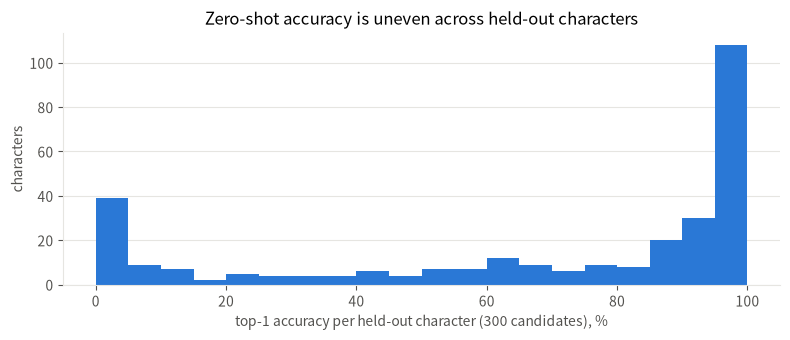

In [22]:
figure, axis = plt.subplots(figsize=(8, 3.5))
axis.hist(100 * per_heldout["top1_within_heldout"], bins=20, color=SERIES_BLUE)
axis.set_xlabel("top-1 accuracy per held-out character (300 candidates), %")
axis.set_ylabel("characters")
axis.set_title("Zero-shot accuracy is uneven across held-out characters")
plt.tight_layout()

In [23]:
heldout_wrong = zero_shot_predictions[zero_shot_predictions["rank_within_heldout"] > 1]
wrong_pairs = Counter(zip(heldout_wrong["true"], heldout_wrong["predicted_within_heldout"]))
pd.DataFrame([(t, p, n, positioned_components(characters.index(t)), positioned_components(characters.index(p)))
              for (t, p), n in wrong_pairs.most_common(15)],
             columns=["true", "predicted", "images", "true components", "predicted components"])

,true,predicted,images,true components,predicted components
0,燕,芯,26,口@none 灬@none,艹@top 心@bottom
1,獣,吠,25,口@none ⺍@none 犬@right 田@none,口@left 犬@right
2,図,回,23,囗@kamae ⺍@none 乂@none,口@none 囗@kamae
3,詐,計,22,言@left 乍@right,言@left 十@right
4,寝,官,22,宀@top 冖@none 又@none,口@none 宀@top
5,冊,升,21,冂@none 廾@none,丿@none 廾@none
6,尋,亜,20,口@right 寸@bottom 工@left,口@none 二@none
7,徳,什,20,彳@left 十@none 心@none 罒@none,亻@left 十@right
8,侃,化,19,亻@left 口@top,亻@left 匕@right
9,呉,只,19,口@none 八@none,口@top 八@bottom


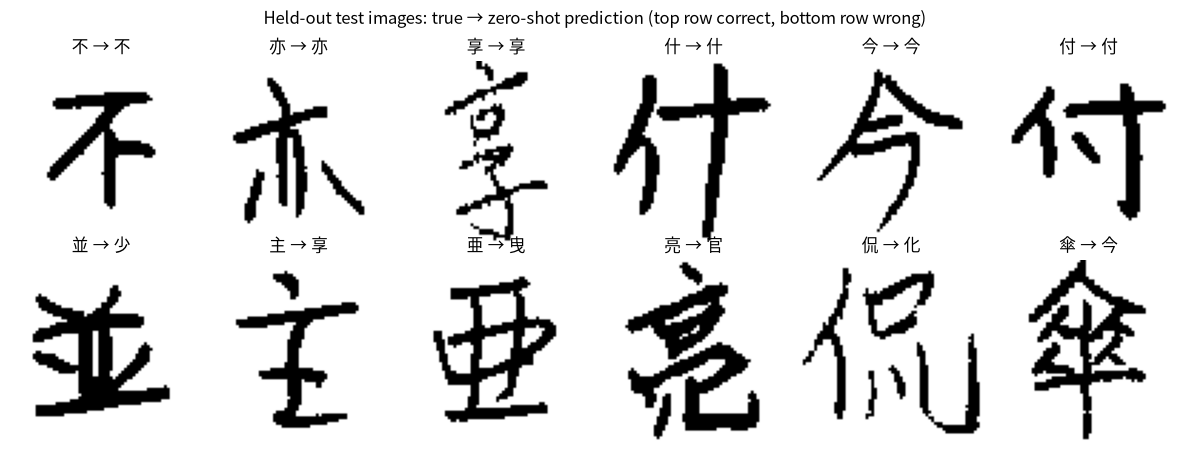

In [24]:
examples = zero_shot_predictions.groupby("true").first().reset_index()
examples = pd.concat([examples[examples["rank_within_heldout"] == 1].head(6),
                      examples[examples["rank_within_heldout"] > 1].head(6)])
figure, axes = plt.subplots(2, 6, figsize=(12, 4.6))
for axis, (_, row) in zip(axes.ravel(), examples.iterrows()):
    axis.imshow(cache.images[row["test_index"]], cmap="gray_r")
    axis.set_title(f"{row['true']} → {row['predicted_within_heldout']}", fontsize=12)
    axis.axis("off")
figure.suptitle("Held-out test images: true → zero-shot prediction (top row correct, bottom row wrong)")
plt.tight_layout()

## 4. Using components at test time: re-ranking the top-5

`scripts/rerank.py`: each of the character head's top-5 candidates gets
`log P(candidate) + weight × component log-likelihood`, where the component log-likelihood measures
how well the candidate's KanjiVG components match the predicted component probabilities (same
matching as section 3). The weight is chosen on the 400 validation writers; the test writers are
scored once with it. Re-ranking cannot fix an image whose true character is outside the top-5.

⚠️ Candidates are limited to the top-5 of the character head, and the weight grid is
0–1 in 9 steps. A wider candidate list or finer grid can change the size of the gain.

In [25]:
rerank = json.loads((RESULTS_DIR / "rerank.json").read_text())
baseline_top1 = runs[runs["model"] == "baseline"].set_index("samples_per_class")["test_top1"]
three_way = pd.DataFrame([{
    "samples_per_class": r["samples_per_class"],
    "baseline": baseline_top1[r["samples_per_class"]],
    "component-aware": r["test_top1_without_rerank"],
    "component-aware + re-ranking": r["test_top1_with_rerank"],
    "top5_ceiling": r["test_top5"],
    "chosen_weight": r["chosen_weight"],
} for r in rerank]).set_index("samples_per_class")
print(len(three_way), "data sizes; test top-1 accuracy")
three_way.round(4)

3 data sizes; test top-1 accuracy


,baseline,component-aware,component-aware + re-ranking,top5_ceiling,chosen_weight
samples_per_class,,,,,
5,0.8887,0.9114,0.9166,0.9881,0.10
20,0.9791,0.9825,0.9829,0.9982,0.10
200,0.9923,0.9929,0.9929,0.9995,0.02


In [26]:
paired_rerank = pd.DataFrame([{
    "samples_per_class": r["samples_per_class"], "answers_changed": r["answers_changed"],
    "fixed": r["fixed"], "broken": r["broken"], "mcnemar_p_value": r["mcnemar_p_value"],
    "error_reduction_pct": 100 * (r["test_top1_with_rerank"] - r["test_top1_without_rerank"])
                           / (1 - r["test_top1_without_rerank"]),
} for r in rerank]).set_index("samples_per_class")
paired_rerank.round(4)

,answers_changed,fixed,broken,mcnemar_p_value,error_reduction_pct
samples_per_class,,,,,
5,1828,854,537,0.0000,5.8911
20,289,132,108,0.1375,2.2642
200,22,11,8,0.6476,0.6912


`fixed` / `broken` compare re-ranked answers with the same model's answers without re-ranking,
on the same test images. ⚠️ The McNemar test treats images as independent; images from the same
writer are correlated, so p-values are optimistic.

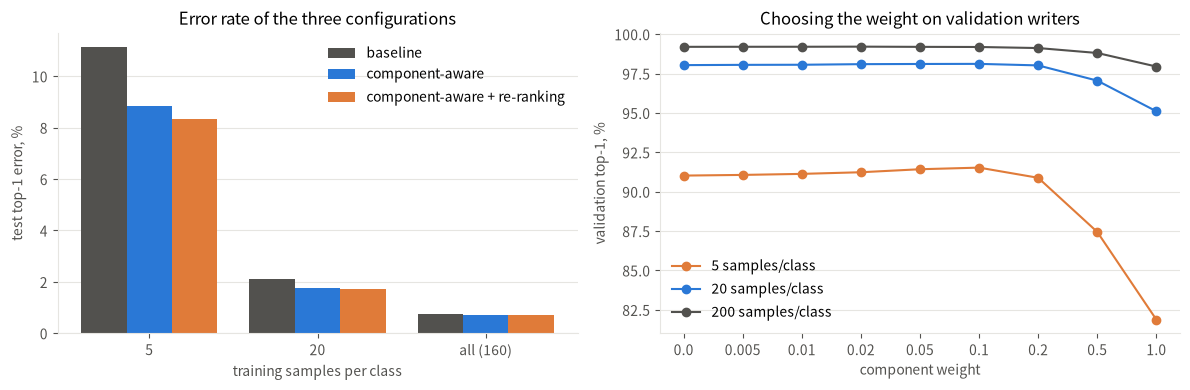

In [27]:
figure, (left, right) = plt.subplots(1, 2, figsize=(12, 4))
error_columns = [("baseline", TEXT_SECONDARY), ("component-aware", SERIES_BLUE),
                 ("component-aware + re-ranking", SERIES_ORANGE)]
positions = np.arange(len(three_way))
for offset, (column, color) in zip([-0.27, 0, 0.27], error_columns):
    left.bar(positions + offset, 100 * (1 - three_way[column]), width=0.27, color=color, label=column)
left.set_xticks(positions, ["5", "20", "all (160)"])
left.set_xlabel("training samples per class")
left.set_ylabel("test top-1 error, %")
left.set_title("Error rate of the three configurations")
left.legend(frameon=False)
for r, color in zip(rerank, [SERIES_ORANGE, SERIES_BLUE, TEXT_SECONDARY]):
    weights = [float(w) for w in r["validation_top1_by_weight"]]
    accuracy = list(r["validation_top1_by_weight"].values())
    right.plot(range(len(weights)), 100 * np.array(accuracy), marker="o", color=color,
               label=f"{r['samples_per_class']} samples/class")
right.set_xticks(range(len(weights)), [str(w) for w in weights])
right.set_xlabel("component weight")
right.set_ylabel("validation top-1, %")
right.set_title("Choosing the weight on validation writers")
right.legend(frameon=False)
plt.tight_layout()

In [28]:
rerank_changes = pd.read_csv(RESULTS_DIR / "rerank_changes.csv")
print(len(rerank_changes), "changed answers")
rerank_changes.groupby(["samples_per_class", "outcome"]).size().unstack(fill_value=0)

2139 changed answers


outcome,broken,fixed,still wrong
samples_per_class,,,
5,537,854,437
20,108,132,49
200,8,11,3


In [29]:
fixed_by_rerank = rerank_changes[(rerank_changes["samples_per_class"] == 5)
                                 & (rerank_changes["outcome"] == "fixed")]
top_fixed = fixed_by_rerank.groupby(["true", "before"]).size().sort_values(ascending=False).head(12)
pd.DataFrame({"images": top_fixed, "true components": [positioned_components(characters.index(t))
              for t, _ in top_fixed.index], "before components": [positioned_components(characters.index(b))
              for _, b in top_fixed.index]})

,,images,true components,before components
true,before,,,
驚,鷲,8,,鳥@bottom
亀,電,4,𠂊@top,日@none 雨@top
腸,暢,4,月@left 昜@right,昜@right
驚,鷺,3,,鳥@bottom
椋,掠,3,木@left 京@right,扌@left 京@right
縞,稿,3,糸@left,禾@left
銭,銃,3,金@left 戋@right,金@left
鋪,舗,3,金@left 甫@right,人@top 甫@right
狙,祖,3,⺨@left 且@right,礻@left 且@right


In [30]:
broken_by_rerank = rerank_changes[(rerank_changes["samples_per_class"] == 5)
                                  & (rerank_changes["outcome"] == "broken")]
top_broken = broken_by_rerank.groupby(["true", "after"]).size().sort_values(ascending=False).head(12)
pd.DataFrame({"images": top_broken, "true components": [positioned_components(characters.index(t))
              for t, _ in top_broken.index], "re-ranked components": [positioned_components(characters.index(a))
              for _, a in top_broken.index]})

,,images,true components,re-ranked components
true,after,,,
童,董,5,立@top,艹@top
釈,秩,4,尺@right,禾@left
着,著,4,丿@none 羊@none,艹@top
雑,維,4,木@bottom 隹@right,糸@left 隹@right
冶,治,3,冫@left 台@right,氵@left 台@right
取,敢,3,又@right 耳@left,攵@right
鷺,驚,3,鳥@bottom,
喬,蕎,3,,艹@top
卵,卯,3,丶@none,丿@none 卩@right
